__Tasks:__
- [x] Collect a MVD (Minimum Viable Data)
    - I'm using the raw data for MOLM-13 screen from this [bioRxiv](https://www.biorxiv.org/content/10.1101/2022.12.14.518457v1)
- [x] Trim reads in FASTQ, count unique sequences, and map to V2 sgRNA library table.
- [ ] Compare with ScreenProcessing

___
    Thu Mar  7 03:55:05 UTC 2024

I have implmented all required features for single-guide and dual-guide designs. Here I want to perform enough tests to make sure I have everything ready to go for other users!

In [1]:
!pip uninstall -y screenpro2

Found existing installation: ScreenPro2 0.2.7
Uninstalling ScreenPro2-0.2.7:
  Successfully uninstalled ScreenPro2-0.2.7


In [2]:
# !pip install git+https://github.com/arcinstitute/screenpro2.git@dual-guide-design
!pip install git+https://github.com/arcinstitute/screenpro2.git

  Cloning https://github.com/arcinstitute/screenpro2.git to /var/tmp/pip-req-build-9whgvw46
  Running command git clone --filter=blob:none --quiet https://github.com/arcinstitute/screenpro2.git /var/tmp/pip-req-build-9whgvw46
  Resolved https://github.com/arcinstitute/screenpro2.git to commit 1a2f26133213f1734088985800df95acf7a59b6d
  Preparing metadata (setup.py) ... done
  Created wheel for ScreenPro2: filename=ScreenPro2-0.2.7-py3-none-any.whl size=18369 sha256=78d89dea7a27ee31384976da679ad112c0689a32872f9bedb0a8e07586953e97
  Stored in directory: /var/tmp/pip-ephem-wheel-cache-aotl0ire/wheels/99/50/50/6dc1f81349ce90badf01c1c93c7639b77879bb6314904147be
Successfully built ScreenPro2


In [3]:
import screenpro as scp

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import biobear as bb
import anndata as ad
import polars as pl
from time import time
from glob import glob

# from pyfaidx import Fasta

In [5]:
import numpy as np

# Collect data
A Minimum Viable Data (MVD)!

In [6]:
import subprocess 

In [7]:
# %%bash 
# mkdir -p DDRi_PRDX1_screens_fastq/

# for fq in `gsutil ls gs://crispr-screens/genome-scale-pooled-v3/DDRi-PRDX1-screens/`; do
#     b=`basename $fq`;
#     echo $b;
#     gsutil cp $fq DDRi_PRDX1_screens_fastq/$b;
# done

In [8]:
# %%bash 
# mkdir -p molm13_exp_fastq/

# for fq in `gsutil ls gs://crispr-screens/genome-scale-pooled-v2/molm13_exp`; do
#     b=`basename $fq`;
#     gsutil cp $fq molm13_exp_fastq/$b;
# done

In [9]:
def oligo_sequence_design():
    """
    """
    ## assuming R1=19, R2=19
    r1 = 'G'+19*'N'
    r2 = 19*'N'
    # r1 = 'G'+19*'N'
    print(f'oligo: {len(r1)*"A"}{len(r2)*"B"}')
    print(f'read1: {r1}{len(r2)*"-"}, length: {len(r1)}')
    print(f'read2: {len(r1)*"-"}{r2}, length: {len(r1)}')
    print()    
    print('A: protospacer A')
    print('B: protospacer B')


In [10]:
oligo_sequence_design()

oligo: AAAAAAAAAAAAAAAAAAAABBBBBBBBBBBBBBBBBBB
read1: GNNNNNNNNNNNNNNNNNNN-------------------, length: 20
read2: --------------------NNNNNNNNNNNNNNNNNNN, length: 20

A: protospacer A
B: protospacer B


## CRISPRi_v3

### Count FASTQ ...

#### test run

In [14]:
res = scp.ngs.fastq_to_count_dual_guide(
    R1_fastq_file_path='DDRi_PRDX1_screen/fastq/i01_R1.fastq.gz',
    R2_fastq_file_path='DDRi_PRDX1_screen/fastq/i01_R2.fastq.gz',
    trim5p_pos1_start=1,
    trim5p_pos1_length=19,
    trim5p_pos2_start=1,
    trim5p_pos2_length=19,
    verbose=True
)

done in 45.707s


In [16]:
res = res.sort('count', descending=True)

In [17]:
res = res.with_columns(
    pl.concat_str(
        [
            pl.col("protospacer_a"),
            pl.col("protospacer_b")
        ],
        separator=";",
    ).alias("sequence"),
)

___

In [34]:
library = pd.read_csv(
    'JR_V3lib_top2_v2.csv', index_col=0
    # 'CRISPRi_dual_human_librarytable_corrected_v2.txt',
    # sep='\t',low_memory=False
).rename(
    columns={'protospacer_A':'protospacer_a','protospacer_B':'protospacer_b'}
)

# library['sequence'] = library.protospacer_a.str[1:] + ';' + library.protospacer_b.str[1:]
# library.protospacer_a = library.protospacer_a.str[1:]


library['sequence'] = library.protospacer_a + ';' + library.protospacer_b.str[1:]
library.protospacer_a = library.protospacer_a
library.protospacer_b = library.protospacer_b.str[1:]

In [36]:
library_top12 = library.query(
    "predictedRank_A not in ['3','5'] & predictedRank_B not in ['4','6']"
).reset_index(drop=True)

In [13]:
# ngs.map_sample_counts_to_library(
#     sample=res.to_pandas(),
#     library=library
# )

In [37]:
res_map = pl.DataFrame(library).join(
        res, on="sequence", how="left"
    )

In [39]:
# {'inner', 'left', 'outer', 'semi', 'anti', 'cross'}

res_unmap = res.join(
        pl.DataFrame(library), on="sequence", how="anti"
    )

In [40]:
100 * \
res_unmap.to_pandas()['count'].fillna(0).sum() / \
int(res.select(pl.sum("count")).to_pandas()['count'])

43.396782763529494

In [41]:
100 * \
res_map.to_pandas()['count'].fillna(0).sum() / \
int(res.select(pl.sum("count")).to_pandas()['count'])

57.447278001834576

In [42]:
res_unmap_remapped_a = res_unmap.join(
    pl.DataFrame(library[['sgID_A','protospacer_a']]), on=["protospacer_a"], how="left"
)

In [43]:
res_unmap_remapped_a.join(
    pl.DataFrame(library[['sgID_B','protospacer_b']]), 
    on=["protospacer_b"], how="left"
).drop_nulls().filter(pl.col("count") > 10)

protospacer_a,protospacer_b,count,sequence,sgID_A,sgID_B
str,str,i64,str,str,str
"""CAAGAGCTAGCCTC…","""CACCGACCGGCACC…",11320,"""CAAGAGCTAGCCTC…","""MLF1_+_1582889…","""UFSP1_-_100487…"
"""CGGGGCCCGCCGCA…","""TGGAGAGCAGGGTC…",269,"""CGGGGCCCGCCGCA…","""NT5C2_-_104952…","""PROC_-_1281764…"
"""GGCCTGCCGGGAGT…","""CTCCTGGGGAGCGC…",221,"""GGCCTGCCGGGAGT…","""NOL11_-_657140…","""ZGPAT_+_623388…"
"""GGAGCTAGGCCGGC…","""GTCGGCCGCCCTAG…",211,"""GGAGCTAGGCCGGC…","""ERAP1_+_961436…","""IFT140_-_16606…"
"""CAGCTCTGGAGTCA…","""GAGCTGACGCCAAG…",168,"""CAGCTCTGGAGTCA…","""GPR85_+_112726…","""SLC38A8_+_8407…"
"""CACGCTGGGTGATC…","""GGCAGTCTTCCGAG…",161,"""CACGCTGGGTGATC…","""C10orf62_+_993…","""EMC6_-_3572123…"
"""CTCAAGGCCGGAGA…","""AGCTCCTAGGACCA…",159,"""CTCAAGGCCGGAGA…","""KIAA2018_-_113…","""SLC34A3_-_1401…"
"""CCGCTGAACCCGGA…","""AGGAGCAGTTCTCA…",149,"""CCGCTGAACCCGGA…","""IMPA1_-_825984…","""SMPX_+_2177621…"
"""ACAGCGTGAAAGGA…","""AAACTGAGACAGTA…",149,"""ACAGCGTGAAAGGA…","""DDX50_+_706610…","""C3AR1_-_821889…"


**conclusion**: these steps could capture recombination events and retain information about 40% of dismissed reads!

#### run...

In [ ]:
from simple_colors import *
print(green('Hello', ['bold']) )

In [44]:
# library = pd.read_csv(
#     # 'CRISPRi_dual_human_librarytable_corrected_v2.txt',
#     # sep='\t',low_memory=False
#     'JR_V3lib_top2_v2.csv',index_col=0
# ).rename(
#     columns={'protospacer_A':'protospacer_a','protospacer_B':'protospacer_b'}
# )

# library['sequence'] = library.protospacer_a.str[1:] + ';' + library.protospacer_b.str[1:]
# library.protospacer_a = library.protospacer_a.str[1:]
# library.protospacer_b = library.protospacer_b.str[1:]



In [48]:
from simple_colors import green

In [50]:
counts = {}

for index in pd.read_csv('DDRi_PRDX1_screen/PRDX1screen_sampleIDs.csv')['index'].to_list():

    print(green(index, ['bold']))
    
    res = scp.ngs.fastq_to_count_dual_guide(
        R1_fastq_file_path=f'DDRi_PRDX1_screen/fastq/{index}_R1.fastq.gz',
        R2_fastq_file_path=f'DDRi_PRDX1_screen/fastq/{index}_R2.fastq.gz',
        trim5p_pos1_start=1,
        trim5p_pos1_length=19,
        trim5p_pos2_start=1,
        trim5p_pos2_length=19,
        verbose=True
    )
    
    res = res.sort('count', descending=True)

    res = res.with_columns(
        pl.concat_str(
            [
                pl.col("protospacer_a"),
                pl.col("protospacer_b")
            ],
            separator=";",
        ).alias("sequence"),
    )

    res_map = pl.DataFrame(library).join(
            res, on="sequence", how="left"
        )

    print("% mapped reads",
        100 * \
        res_map.to_pandas()['count'].fillna(0).sum() / \
        int(res.select(pl.sum("count")).to_pandas()['count'])
    )

    # {'inner', 'left', 'outer', 'semi', 'anti', 'cross'}

    res_unmap = res.join(
            pl.DataFrame(library), on="sequence", how="anti"
        )

    print("% unmapped reads",
        100 * \
        res_unmap.to_pandas()['count'].fillna(0).sum() / \
        int(res.select(pl.sum("count")).to_pandas()['count'])
    )
    
    res_unmap_remapped_a = res_unmap.join(
        pl.DataFrame(library[['sgID_A','protospacer_a']]), on=["protospacer_a"], how="left"
    )

    res_recomb_events = res_unmap_remapped_a.join(
        pl.DataFrame(library[['sgID_B','protospacer_b']]), 
        on=["protospacer_b"], how="left"
    )
    
    print("% fully remapped recombination events",
        100 * \
        res_recomb_events.drop_nulls().to_pandas()['count'].fillna(0).sum() / \
        int(res.select(pl.sum("count")).to_pandas()['count'])
    )
    
    counts[index] = {'full': res,'mapped': res_map,'recomb': res_recomb_events}

i01
done in 41.599s
% mapped reads 57.447278001834576
% unmapped reads 43.396782763529494
% fully remapped recombination events 21.715396993534213
i02
done in 48.793s
% mapped reads 57.540784742915775
% unmapped reads 43.32141033554902
% fully remapped recombination events 21.731927489590703
i03
done in 76.401s
% mapped reads 58.411860044248364
% unmapped reads 42.42914875479367
% fully remapped recombination events 20.74990109467006
i04
done in 87.491s
% mapped reads 58.15306234727304
% unmapped reads 42.69218175707599
% fully remapped recombination events 20.804734423246803
i05
done in 73.116s
% mapped reads 58.36800895766825
% unmapped reads 42.472820563007694
% fully remapped recombination events 20.75434434526048
i06
done in 58.916s
% mapped reads 58.35467525889862
% unmapped reads 42.48512512075258
% fully remapped recombination events 20.805996757806277
i07
done in 64.981s
% mapped reads 58.59611477277857
% unmapped reads 42.252127099596436
% fully remapped recombination events 

In [51]:
import pickle

In [52]:
obj = counts

file_name = 'DDRi_PRDX1_screen/counts_full-v2.pkl'

with open(file_name, 'wb') as file:
    pickle.dump(obj, file)
    print(f'Object successfully saved to "{file_name}"')

Object successfully saved to "DDRi_PRDX1_screen/counts_full-v2.pkl"


___

In [53]:
meta = pd.read_excel('DDRi_PRDX1_screen/PRDX1samplesheet_incgrowth.xlsx').set_index('index')

In [54]:
counts_mat = pd.concat([
    counts[sample_id]['mapped'].to_pandas().set_index('sgID_AB')['count'].rename(sample_id) 
    for sample_id in counts.keys()
],axis=1).fillna(0)

In [55]:
adata = ad.AnnData(
    X = counts_mat.T,
    var = library.set_index('sgID_AB').rename(columns={'gene':'target'}),
    obs = meta
)

adata.var['targetType'] = ''
adata.var.loc[adata.var.target.eq('negative_control'),'targetType']  = 'negCtrl'
adata.var.loc[~adata.var.target.eq('negative_control'),'targetType'] = 'gene'
adata.var.index.name = None


adata.obs.treatment = adata.obs.treatment.str.replace('-','T0')
adata.obs = adata.obs.rename(columns={'treatment':'condition','rep':'replicate'})

adata.obs['pop_doublings'] = meta['pop doublings'].replace('-',np.nan).astype(float)

del adata.obs['pop doublings']

In [56]:
adata.write_h5ad('DDRi_PRDX1_screen/adata-v2.h5ad.gz',compression='gzip')

___

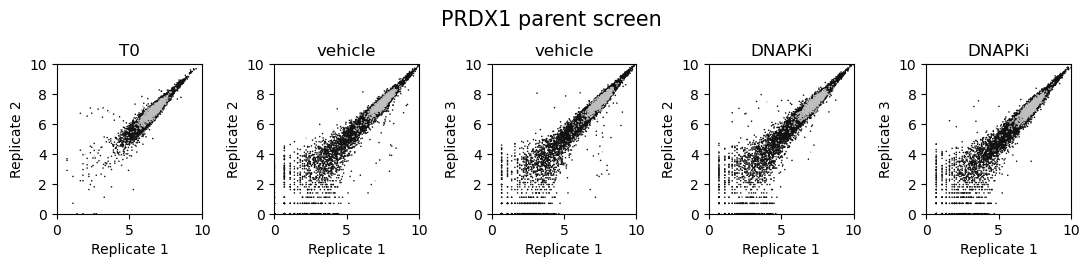

In [58]:
fig, axes = plt.subplots(ncols=5,
                         figsize=(13,3), 
                         gridspec_kw={'wspace': 0.5, 'left': 0.12,'top':.8,'bottom':.3}, 
                         # sharey=True
                        )
scp.pl.plotReplicateScatter(axes[0], adata, 'i01','i02','T0',min_val=0,max_val=10)
scp.pl.plotReplicateScatter(axes[1], adata, 'i03','i04','vehicle',min_val=0,max_val=10)
scp.pl.plotReplicateScatter(axes[2], adata, 'i03','i05','vehicle',min_val=0,max_val=10)
scp.pl.plotReplicateScatter(axes[3], adata, 'i06','i07','DNAPKi',min_val=0,max_val=10)
scp.pl.plotReplicateScatter(axes[4], adata, 'i06','i08','DNAPKi',min_val=0,max_val=10)

fig.suptitle('PRDX1 parent screen',fontsize=15)

# plt.savefig('NAC_counts_qc.pdf',bbox_inches='tight')
plt.show()


___

In [59]:
import screenpro as scp

In [60]:
adata_PRDX1KO = adata[adata.obs['cell line'].eq('PRDX1KO')].copy()
adata_parent  = adata[adata.obs['cell line'].eq('parent')].copy()

In [61]:
screen0 = scp.ScreenPro(adata_parent)
screen = scp.ScreenPro(adata_parent[adata_parent.obs.replicate.isin([1,2])].copy(),n_reps=2)

In [62]:
screen.calculateDrugScreen(
    t0='T0', untreated='vehicle', treated='DNAPKi',
    db_untreated = 7.8,
    db_treated = 7.5,
    score_level='compare_reps'
)


	vehicle vs T0
	DNAPKi vs T0
	DNAPKi vs vehicle


In [63]:
growth_factor_table = scp.utils.calculateGrowthFactor(screen0, untreated = 'vehicle', treated = 'DNAPKi', db_rate_col = 'pop_doublings')

In [64]:
screen.pdata = ad.AnnData(
    X=pd.concat([
        scp.ps.runPhenoScoreForReplicate(screen,'T0', 'vehicle','gamma',growth_factor_table).add_prefix('gamma_'),
        scp.ps.runPhenoScoreForReplicate(screen,'T0', 'DNAPKi','tau',growth_factor_table).add_prefix('tau_'),
        scp.ps.runPhenoScoreForReplicate(screen0,'vehicle', 'DNAPKi','rho',growth_factor_table).add_prefix('rho_')
    ],axis=1).T,
    var=screen.adata.var
)

screen.pdata.obs['score'] = screen.pdata.obs.index.str.split('_').str[0]
screen.pdata.obs['replicate'] = screen.pdata.obs.index.str.split('_').str[2]

scp.utils.find_low_counts(screen0.adata)

screen.pdata = screen.pdata[:,~screen0.adata.var.low_count].copy()

2314 variables with less than 50 reads in either replicates / experiment


/opt/conda/envs/screenpro2/lib/python3.9/site-packages/scanpy/preprocessing/_simple.py:351: RuntimeWarning: invalid value encountered in log1p
  np.log1p(X, out=X)
/opt/conda/envs/screenpro2/lib/python3.9/site-packages/scanpy/preprocessing/_simple.py:351: RuntimeWarning: invalid value encountered in log1p
  np.log1p(X, out=X)


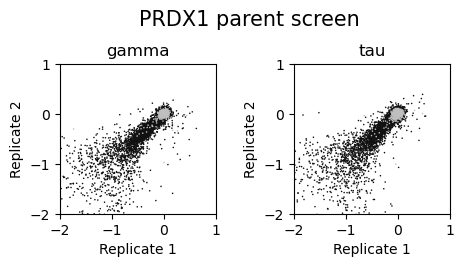

In [65]:
fig, axes = plt.subplots(ncols=2,
                         figsize=(5,3), 
                         gridspec_kw={'wspace': 0.5, 'left': 0.12,'top':.8,'bottom':.3}, 
                         # sharey=True
                        )
scp.pl.plotReplicateScatter(axes[0], screen.pdata, 'gamma_replicate_1','gamma_replicate_2','gamma',max_val=1)
scp.pl.plotReplicateScatter(axes[1], screen.pdata, 'tau_replicate_1','tau_replicate_2','tau',max_val=1)


fig.suptitle('PRDX1 parent screen',fontsize=15)

# plt.savefig('NAC_counts_qc.pdf',bbox_inches='tight')
plt.show()

In [66]:
scp.utils.find_low_counts(screen0.adata)

2314 variables with less than 50 reads in either replicates / experiment


In [67]:
sel = ['target','score','ttest pvalue']# BH adj_pvalue # ttest pvalue
gamma = screen.phenotypes['compare_reps']['gamma:vehicle_vs_T0'].loc[:,sel].reset_index(drop=True)

tau = screen.phenotypes['compare_reps']['tau:DNAPKi_vs_T0'].loc[:,sel].reset_index(drop=True)

rho = screen.phenotypes['compare_reps']['rho:DNAPKi_vs_vehicle'].loc[:,sel].reset_index(drop=True)

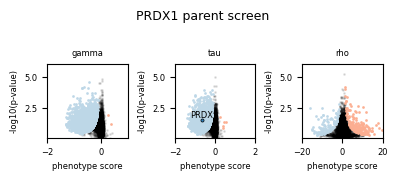

In [68]:
# Create subplots and specify the size
fig, (ax1,ax2,ax3) = plt.subplots(1,3,figsize=(4, 1.8))

scp.pl.plot_volcano(ax1, gamma,threshold=5,xlim_l=-2, xlim_r=1,ctrl_label='negative_control')
ax1.grid(False)
ax1.get_legend().remove()
ax1.set_title('gamma')

scp.pl.plot_volcano(ax2, tau,threshold=5,xlim_l=-2, xlim_r=2,ctrl_label='negative_control')
scp.pl.label_sensitivity_hit(ax2,tau,'PRDX1',threshold=5,size=5,size_txt=6,t_x=-.6,t_y=.2,ctrl_label='negative_control')

ax2.grid(False)
ax2.get_legend().remove()
ax2.set_title('tau')

scp.pl.plot_volcano(ax3, rho,threshold=5,xlim_l=-20, xlim_r=20,ctrl_label='negative_control')
# label_resistance_hit(ax2,rho,'TTC1',size=5,size_txt=6,t_x=.1)
# label_sensitivity_hit(ax2,rho,'CLHC1',size=5,size_txt=6,t_y=.1)

ax3.grid(False)
ax3.get_legend().remove()
ax3.set_title('rho')


for ax in [ax1,ax2,ax3]:
    for item in ([ax.title, ax.xaxis.label, ax.yaxis.label] + ax.get_xticklabels() + ax.get_yticklabels()):
        item.set_fontsize(6)

fig.suptitle('PRDX1 parent screen',fontsize=9)
plt.tight_layout()
# Show the plot
plt.show()

___

In [69]:
adata_old = ad.read_h5ad('DDRi_PRDX1_screen/old_adata_counts.h5ad.gz')

In [70]:
# adata_old.to_df().T[['i01']].index.str.split('++')

In [71]:
i01_screenpro2_count = adata.to_df().T[['i01']]

In [72]:
i01_old_count = adata_old.to_df().T[['i01']].rename(columns={'i01':'i01_old'})

i01_old_count.index = i01_old_count.index.str.split('\+\+').str[1]

In [73]:
i01_ol_df = pd.concat([
    i01_old_count,
    i01_screenpro2_count
    ]
,axis=1)

<AxesSubplot: xlabel='i01_old', ylabel='i01'>

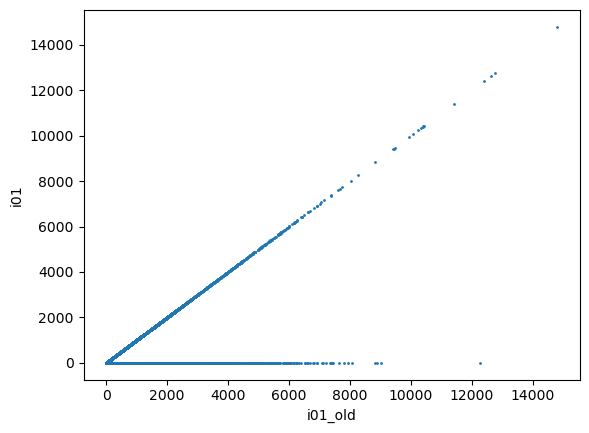

In [74]:
i01_ol_df.plot.scatter('i01_old','i01',s=1)

In [77]:
i01_ol_df.query('i01 == 0 & i01_old > 0').sum()

index
i01_old    3469797.0
i01              0.0
dtype: float64

### 

## CRISPRi_v2

### Count FASTQ ...

In [12]:
# !wget https://raw.githubusercontent.com/mhorlbeck/ScreenProcessing/master/library_reference/CRISPRi_v2_human.trim_1_29_forward.fa

# !mkdir -p ../../../ScreenPro2/library_reference
# !mv CRISPRi_v2_human.trim_1_29_forward.fa \
#     ../../../ScreenPro2/library_reference/CRISPRi_v2_human.trim_1_29_forward.fasta

In [13]:
fasta_file_path = '../../../ScreenPro2/library_reference/CRISPRi_v2_human.trim_1_29_forward.fasta'

In [14]:
ls '../../../ScreenPro2/library_reference'

CRISPRi_v2_human.trim_1_29_forward.fasta


In [15]:
# !cat {fasta_file_path} | wc -l

In [16]:
library = bb.FastaReader(fasta_file_path)

In [17]:
# library_fa = Fasta(fasta_file_path)

In [18]:
# pd.DataFrame([ (sgId, str(seq)) for sgId, seq in library_fa.items()],columns=['sgId','sequence'])

In [19]:
# library_fa.keys()

In [20]:
# library = pd.DataFrame(library_fa.items())

In [21]:
# library

In [22]:
library = pd.read_csv('../../../ScreenPro2/library_tables/CRISPRi_v2_human_librarytable.txt.gz',sep='\t')
library.sequence = library.sequence.str.upper().str[1:]

library_full = library.copy()

library = library.drop_duplicates('sequence',keep='first').set_index('sequence')

### Get Counts

Note: `Upper` helped to increase the mapping efficiency!

In [23]:
slice_seq = (2,19)

In [24]:
counts = {}

start, length = slice_seq

for fq_file in glob('molm13_exp_fastq/*'):
    sample_id = fq_file.split('/')[1].split('.')[0]
    
    print(f"\033[1m{sample_id}\033[0m")
    t0 = time()
    
    session = bb.connect()

    print("start counting ...")
    
    df_cnt = session.sql(f"""
    SELECT substr(f.sequence, {start}, {length}) AS sequence, COUNT(*) as count
    FROM fastq_scan('{fq_file}') f
    GROUP BY substr(f.sequence, {start}, {length})
    """
    ).to_polars()    
    
    df_cnt = df_cnt.to_pandas()
    print(f'# of sequences: {df_cnt.shape[0]}')
    print(f'total counts: {df_cnt["count"].sum()}')
    
    df_mapped = ngs.map_sample_counts_to_library(library,df_cnt)
    
    counts[sample_id] = df_mapped
    
    print("done in %0.3fs" % (time() - t0))

DMSO_Rep2
start counting ...
# of sequences: 1231293
total counts: 89965203
% mapped sequences: 0.90
% non-mapped sequences: 0.10
done in 77.384s
T0_Rep1
start counting ...
# of sequences: 1340346
total counts: 88608358
% mapped sequences: 0.90
% non-mapped sequences: 0.10
done in 77.443s
DAC_Rep1
start counting ...
# of sequences: 1168186
total counts: 87165105
% mapped sequences: 0.90
% non-mapped sequences: 0.10
done in 75.859s
DMSO_Rep1
start counting ...
# of sequences: 1370378
total counts: 100710735
% mapped sequences: 0.89
% non-mapped sequences: 0.11
done in 88.455s
DAC_Rep2
start counting ...
# of sequences: 1273923
total counts: 81834220
% mapped sequences: 0.89
% non-mapped sequences: 0.11
done in 72.046s
DMSO_Rep2
start counting ...
# of sequences: 56765
total counts: 100000
% mapped sequences: 0.90
% non-mapped sequences: 0.10
done in 0.382s
T0_Rep2
start counting ...
# of sequences: 1465160
total counts: 94726489
% mapped sequences: 0.90
% non-mapped sequences: 0.10
done

/home/jupyter/CRISPR-projects/ScreenPro-Benchmarking/analysis/1a-dCas9-genome-scale-libraries/../../../ScreenPro2/screenpro/ngs.py:63: RuntimeWarning: invalid value encountered in scalar divide
  print(f"% mapped sequences: {n_mapped_counts/sample['count'].sum():.2f}")
/home/jupyter/CRISPR-projects/ScreenPro-Benchmarking/analysis/1a-dCas9-genome-scale-libraries/../../../ScreenPro2/screenpro/ngs.py:64: RuntimeWarning: invalid value encountered in scalar divide
  print(f"% non-mapped sequences: {n_unmapped_counts/sample['count'].sum():.2f}")


### Make `AnnData`

In [58]:
counts['DMSO_Rep1']

,sgId,sublibrary,gene,transcripts,counts
sequence,,,,,
GAGACCCAGCGCTAACCAG,A1BG_-_58858617.23-P1,h3_top5,A1BG,P1,203
GGGCACCCAGGAGCGGTAG,A1BG_-_58858788.23-P1,h3_top5,A1BG,P1,359
CTCCGGGCGACGTGGAGTG,A1BG_+_58858964.23-P1,h3_top5,A1BG,P1,513
AACCAGGGGTGCCCAAGGG,A1BG_-_58858630.23-P1,h3_top5,A1BG,P1,328
GCGAGGAACCGCCCAGCAA,A1BG_+_58858549.23-P1,h3_top5,A1BG,P1,223
...,...,...,...,...,...
CTACTCCGCCCCGCGGGAG,non-targeting_03785,h7_supp5,negative_control,na,0
TGGCCGTTCATGGGACCGG,non-targeting_03786,h7_supp5,negative_control,na,0
AACTCTGTAGAAGGGACCG,non-targeting_03787,h7_supp5,negative_control,na,0


In [27]:
counts_df = pd.concat(dict([(name,df['counts']) for name, df in counts.items()]),axis=1)

In [28]:
adata = ad.AnnData(X=counts_df.T,var=library)

adata = adata[:,adata.to_df().sum().gt(0)].copy()

### Compare counts with ScreenProcessing

In [29]:
# !wget 'https://raw.githubusercontent.com/GilbertLabUCSF/Decitabine-treatment/main/DAC/CRISPRi-screen/molm13_exp/mergedcountstable.txt'

In [30]:
screenprocessing_counts = pd.read_csv(
    'mergedcountstable.txt', 
    sep='\t', 
    header=list(range(2)),
    index_col=list(range(1))
)

screenprocessing_counts = screenprocessing_counts[screenprocessing_counts.sum(axis=1).gt(0)]

In [31]:
from venn import venn

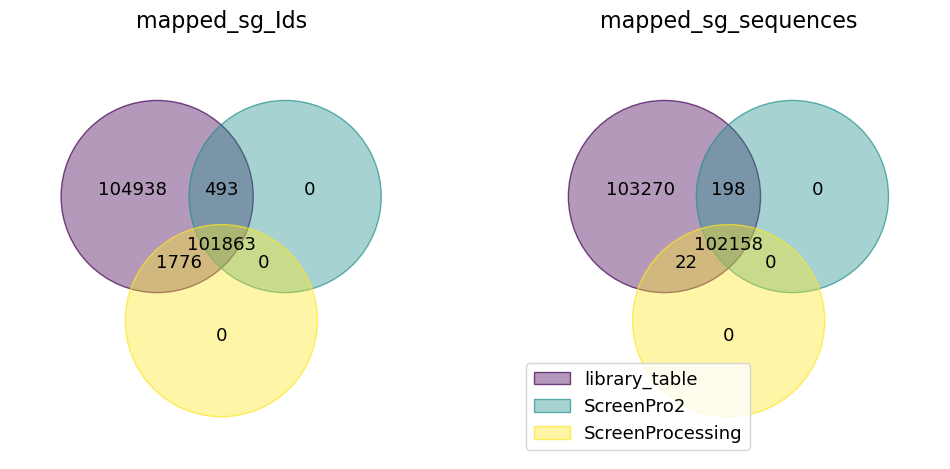

In [32]:
fig,(ax,bx) = plt.subplots(1,2,figsize=(12,6))
venn({
    'library_table':set(library_full.sgId),
    'ScreenPro2':set(adata.var.sgId),
    'ScreenProcessing':set(screenprocessing_counts.index)#.loc[adata.var.sgId,:]
},legend_loc=None,ax=ax)
ax.set_title('mapped_sg_Ids',fontsize=16)

venn({
    'library_table':set(library_full.sequence),
    'ScreenPro2':set(adata.var.index),
    'ScreenProcessing':set(library_full.set_index('sgId').loc[screenprocessing_counts.index,'sequence'].to_list())
},legend_loc='best',ax=bx)
bx.set_title('mapped_sg_sequences',fontsize=16)
plt.show()

In [33]:
# set(adata.var.sgId) - set(screenprocessing_counts.index)#.loc[adata.var.sgId,:]

In [34]:
tmp1 = set(library_full.set_index('sgId').loc[screenprocessing_counts.index,'sequence'].to_list()) - set(adata.var.index)

In [35]:
sorted_tmp = adata[:,list(set(adata.var.index) - set(library_full.set_index('sgId').loc[screenprocessing_counts.index,'sequence'].to_list()))].to_df().sum().sort_values().index

In [36]:
fq_file

'molm13_exp_fastq/DMSO_Rep2.fasta.gz'

In [37]:
# fq2fa_file = fq_file.replace('fastq.gz','fasta.gz')

In [38]:
# !seqkit fq2fa -j 6 {fq_file} -o {fq2fa_file}

In [39]:
# # df_fq = ngs.fastq_to_dataframe(
#     fq_file,
#     engine='biobear'
# )

In [40]:
# !zcat {fq_file} | wc -l 

In [41]:
# 378905956 / 4

In [42]:
# df_fq = bb.FastqReader(fq_file,compression=Compression.GZIP).to_polars()

In [43]:
# df_fq.shape

In [44]:
# screenprocessing_counts['T0']['Rep2'].sum() / 89965203

In [45]:
# adata.to_df().loc['T0_Rep2'].sum() / 89965203

<AxesSubplot: >

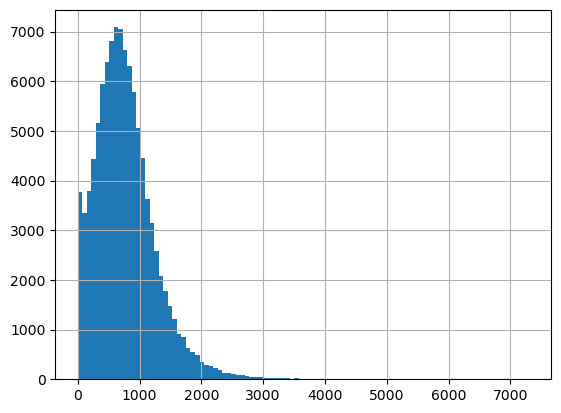

In [ ]:
screenprocessing_counts['T0']['Rep1'].hist(bins=100)

<AxesSubplot: >

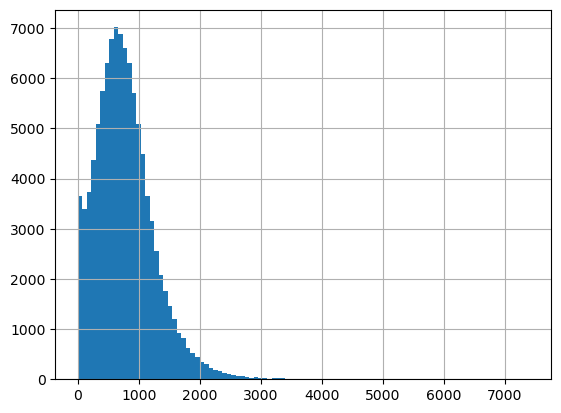

In [ ]:
adata.to_df().loc['T0_Rep1'].hist(bins=100)

In [50]:
screenprocessing_counts['T0']['Rep1']

sgId
A1BG_+_58858549.23-P1     428
A1BG_+_58858964.23-P1     518
A1BG_+_58864367.23-P2     875
A1BG_-_58858617.23-P1     303
A1BG_-_58858630.23-P1     435
                         ... 
non-targeting_01889      1151
non-targeting_01890       545
non-targeting_01892       686
non-targeting_01893      1318
non-targeting_01894      1274
Name: Rep1, Length: 103639, dtype: int64

In [55]:
adata.var.set_index()#.loc['T0_Rep1']

,sgId,sublibrary,gene,transcripts
sequence,,,,
GAGACCCAGCGCTAACCAG,A1BG_-_58858617.23-P1,h3_top5,A1BG,P1
GGGCACCCAGGAGCGGTAG,A1BG_-_58858788.23-P1,h3_top5,A1BG,P1
CTCCGGGCGACGTGGAGTG,A1BG_+_58858964.23-P1,h3_top5,A1BG,P1
AACCAGGGGTGCCCAAGGG,A1BG_-_58858630.23-P1,h3_top5,A1BG,P1
GCGAGGAACCGCCCAGCAA,A1BG_+_58858549.23-P1,h3_top5,A1BG,P1
...,...,...,...,...
GCCCGCCGACAAAGGTTGG,non-targeting_01890,h7_top5,negative_control,na
AAGGCGCCTCGTATAAGGC,non-targeting_01892,h7_top5,negative_control,na
GACACGGGCGAAGGGATAA,non-targeting_01893,h7_top5,negative_control,na


In [48]:
# adata.var.sgId.to_list()

In [49]:
# screenprocessing_counts#.loc[adata.var.sgId,:]

In [66]:
def plot_count_benchmark():
    pass
    #screen, growth_factor_table, score, cond1, cond2, get_z_score, title):
#     screenprocessing_results = screen.phenotypes['phenotypetable'][score]

#     screenpro2_results = scp.ps.runPhenoScoreForReplicate(
#         screen,cond1,cond2,
#         score,
#         growth_factor_table,
#         get_z_score=get_z_score
#     ).loc[screenprocessing_results.index,:]#.add_prefix('hl60_gamma_')

#     fig, ax = plt.subplots(figsize=(3.7,3.7))

#     ax.scatter(
#         x=screenprocessing_results['Rep1'],
#         y=screenpro2_results['replicate_1'],
#         facecolors='#3182bd',
#         s=3,c=almost_black
#     )
#     ax.set_xlabel('ScreenProcessing')
#     ax.set_ylabel('ScreenPro2\nscore')

#     ax.axline((0, 0), slope=1)

#     # ax.set_xlim(-3.5,3.5)
#     # ax.set_ylim(-3.5,3.5)

#     fig.suptitle(title,fontsize=12)

#     # plt.savefig('NAC_counts_qc.pdf',bbox_inches='tight')
#     # plt.tight_layout()
#     plt.show()

In [68]:
plot_count_benchmark()

# 

In [25]:
%load_ext watermark
%watermark
%watermark --iversions

Last updated: 2024-02-28T20:57:25.453134+00:00

Python implementation: CPython
Python version       : 3.9.18
IPython version      : 8.18.1

Compiler    : GCC 11.2.0
OS          : Linux
Release     : 5.10.0-28-cloud-amd64
Machine     : x86_64
Processor   : 
CPU cores   : 16
Architecture: 64bit

polars    : 0.20.10
sys       : 3.9.18 (main, Sep 11 2023, 13:41:44) 
[GCC 11.2.0]
pandas    : 1.5.3
biobear   : 0.15.3
anndata   : 0.10.5.post1
matplotlib: 3.6.3
screenpro : 0.2.6

